In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, f1_score, classification_report, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
import json

In [2]:


# Login using e.g. `huggingface-cli login` to access this dataset
df = pd.read_csv("hf://datasets/mstz/german/loan/train.csv")

df.isna().sum()

checking_account_status              0
account_life_in_months               0
credit_status                        0
loan_purpose                         0
current_credit                       0
current_savings                      0
employed_since                       0
installment_rate_percentage          0
is_male                              0
marital_status                       0
guarantors                           0
years_living_in_current_residence    0
age                                  0
installment_plans                    0
housing_status                       0
nr_credit_accounts_in_bank           0
job_status                           0
number_of_people_in_support          0
has_registered_phone_number          0
is_foreign                           0
loan_granted                         0
dtype: int64

In [3]:
for c in df.columns:
    print(f"Column '{c}' has {df[c].nunique()} unique values")
    print(df[c].unique())

Column 'checking_account_status' has 4 unique values
[1 2 0 3]
Column 'account_life_in_months' has 33 unique values
[ 6 48 12 42 24 36 30 15  9 10  7 60 18 45 11 27  8 54 20 14 33 21 16  4
 47 13 22 39 28  5 26 72 40]
Column 'credit_status' has 5 unique values
[4 2 3 0 1]
Column 'loan_purpose' has 10 unique values
['radio/television' 'education' 'furniture/equipment' 'new car' 'used car'
 'business' 'domestic appliances' 'repairs' 'others' 'retraining']
Column 'current_credit' has 921 unique values
[ 1169  5951  2096  7882  4870  9055  2835  6948  3059  5234  1295  4308
  1567  1199  1403  1282  2424  8072 12579  3430  2134  2647  2241  1804
  2069  1374   426   409  2415  6836  1913  4020  5866  1264  1474  4746
  6110  2100  1225   458  2333  1158  6204  6187  6143  1393  2299  1352
  7228  2073  5965  1262  3378  2225   783  6468  9566  1961  6229  1391
  1537  1953 14421  3181  5190  2171  1007  1819  2394  8133   730  1164
  5954  1977  1526  3965  4771  9436  3832  5943  1213  15

In [4]:

X = df.drop('loan_granted', axis=1)
y = df['loan_granted']

binary_features = ['is_male', 'is_foreign', 'has_registered_phone_number']
X[binary_features] = X[binary_features].astype(int)

# 2. Feature continue e ordinali numeriche (da scalare)
colonne_da_scalare = [
    'account_life_in_months', 
    'current_credit', 
    'age',
    'installment_rate_percentage',
    'years_living_in_current_residence',
    'nr_credit_accounts_in_bank'
]

# 3. Colonne da NON passare a get_dummies (quelle da scalare + binarie + number_of_people_in_support)
escluse_da_dummies = colonne_da_scalare + binary_features + ['number_of_people_in_support']
colonne_dummies = [c for c in X.columns if c not in escluse_da_dummies]

# One-Hot Encoding solo sulle vere categoriche a più livelli (convertite in 0/1 interi)
X = pd.get_dummies(X, columns=colonne_dummies, drop_first=True, dtype=int)




# 5. Divisione in Training e Test Set (stratificata per mantenere le proporzioni del target)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

scaler = StandardScaler()

# 3. Calcola media/varianza e scala SOLO sul Train Set
X_train[colonne_da_scalare] = scaler.fit_transform(X_train[colonne_da_scalare])

# 4. Usa le stesse proporzioni trovate nel Train per scalare il Test Set
X_test[colonne_da_scalare] = scaler.transform(X_test[colonne_da_scalare])

categorical_features = [
    i for i, c in enumerate(X_train.columns)
    if c not in colonne_da_scalare
]
print(f"Categorical features: {categorical_features}")




Categorical features: [3, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44]


In [ ]:
from sklearn.svm import SVC



svm = SVC(kernel='poly', C=1.0, random_state=42, class_weight='balanced')


svm.fit(X_train, y_train)


y_pred = svm.predict(X_test)
y_pred_train = svm.predict(X_train)

#Valutazione delle performance dell'Oracolo sul Test Set
print('Test Accuracy: %.3f' % accuracy_score(y_test, y_pred))
print('Test F1-score:', f1_score(y_test, y_pred, average=None))
print(classification_report(y_test, y_pred))


Test Accuracy: 0.795
Test F1-score: [0.84981685 0.67716535]
              precision    recall  f1-score   support

           0       0.87      0.83      0.85       140
           1       0.64      0.72      0.68        60

    accuracy                           0.80       200
   macro avg       0.76      0.77      0.76       200
weighted avg       0.80      0.80      0.80       200



In [6]:
from RuleTree.tree.TrepanClassifierOptimized import TrepanClassifierOptimized
from RuleTree.stumps.classification.MofNTrepanStumpClassifierOptimized import MofNTrepanStumpClassifierOptimized
trepan_clf = TrepanClassifierOptimized(estimator = svm,  base_stumps=MofNTrepanStumpClassifierOptimized(max_conditions=3), s_min=1300,  max_internal_nodes=2, random_state=42, categorical_features=categorical_features)
trepan_clf.fit(X_train, y_train)
y_pred_trepan = trepan_clf.predict(X_test.values)
print('Accuracy %s' % accuracy_score(y_test, y_pred_trepan))
print('F1-score %s' % f1_score(y_test, y_pred_trepan, average=None))
print(classification_report(y_test, y_pred_trepan))
fidelity = accuracy_score(y_pred, y_pred_trepan)
print("The fidelity respect to the oracle is %s" % fidelity)

Accuracy 0.755
F1-score [0.83389831 0.53333333]
              precision    recall  f1-score   support

           0       0.79      0.88      0.83       140
           1       0.62      0.47      0.53        60

    accuracy                           0.76       200
   macro avg       0.71      0.67      0.68       200
weighted avg       0.74      0.76      0.74       200

The fidelity respect to the oracle is 0.82


In [7]:

trepan_clf.print_trepan_rules(feature_names=X.columns, scaled_columns=colonne_da_scalare, scaler=scaler)


  REGOLE GLOBALI ESTRATTE DA TREPAN
  (VALORI RISCALATI ALLA SCALA ORIGINALE)
REGOLA 1 [Nodo ID: Rll]:
  IF  (1-of-{ current_credit <= 12682.766, employed_since_3 == 1.0 }}) AND 
      (1-of-{ checking_account_status_1 == 0.0, credit_status_4 == 1.0, guarantors_2 == 1.0 }})
  THEN Predizione = 0
  [Fedeltà: 77.33%, Copertura: 80.50%]

REGOLA 2 [Nodo ID: Rlr]:
  IF  (1-of-{ current_credit <= 12682.766, employed_since_3 == 1.0 }}) AND 
      (NOT (1-of-{ checking_account_status_1 == 0.0, credit_status_4 == 1.0, guarantors_2 == 1.0 }}))
  THEN Predizione = 1
  [Fedeltà: 78.15%, Copertura: 18.88%]

REGOLA 3 [Nodo ID: Rr]:
  IF  (NOT (1-of-{ current_credit <= 12682.766, employed_since_3 == 1.0 }}))
  THEN Predizione = 1
  [Fedeltà: 82.69%, Copertura: 0.62%]



In [8]:
from sklearn.tree import DecisionTreeClassifier

# Training del Decision Tree
dt_clf = DecisionTreeClassifier(random_state=42, max_leaf_nodes=3)
dt_clf.fit(X_train, y_pred_train)

# Predizioni
y_pred_dt = dt_clf.predict(X_test)

# Metriche
print('Accuracy %s' % accuracy_score(y_test, y_pred_dt))
print('F1-score %s' % f1_score(y_test, y_pred_dt, average=None))
print(classification_report(y_test, y_pred_dt))

fidelity = accuracy_score(y_pred, y_pred_dt)
print("The fidelity respect to the oracle is %s" % fidelity)

Accuracy 0.725
F1-score [0.80701754 0.52173913]
              precision    recall  f1-score   support

           0       0.79      0.82      0.81       140
           1       0.55      0.50      0.52        60

    accuracy                           0.72       200
   macro avg       0.67      0.66      0.66       200
weighted avg       0.72      0.72      0.72       200

The fidelity respect to the oracle is 0.75


In [9]:
import time

# Fissa un numero di nodi interpretabile
nodi = 2

smin_da_testare = [1000,1100,1200,1300,1400,1500,1600,1700,1800,1900,2000,2100,2200,2300,2400,2500,2600,2700,2800,2900,3000,4000,5000,6000,7000,8000,9000]
risultati_smin = []

for s in smin_da_testare:
    trepan_clf = TrepanClassifierOptimized(
        estimator=svm, 
        base_stumps=MofNTrepanStumpClassifierOptimized(max_conditions=3),
        s_min=s, 
        max_internal_nodes=nodi,
        epsilon=0.01,
        delta=0.01, 
        min_real_samples=100, # Lascia questo fisso
        random_state=42,
        categorical_features=categorical_features
    )
    
    t0 = time.time()
    trepan_clf.fit(X_train, y_train)
    tempo = time.time() - t0
    
    y_pred_trepan = trepan_clf.predict(X_test.values)
    fid = accuracy_score(y_pred, y_pred_trepan) # Fedeltà all'oracolo
    
    risultati_smin.append({'S_min': s, 'Fidelity': fid, 'Time (s)': tempo})
    print(f"S_min: {s:4d} | Fidelity: {fid:.3f} | Time: {tempo:.2f}s")

S_min: 1000 | Fidelity: 0.800 | Time: 0.32s
S_min: 1100 | Fidelity: 0.795 | Time: 0.31s
S_min: 1200 | Fidelity: 0.780 | Time: 0.34s
S_min: 1300 | Fidelity: 0.820 | Time: 0.37s
S_min: 1400 | Fidelity: 0.805 | Time: 0.39s
S_min: 1500 | Fidelity: 0.820 | Time: 0.40s
S_min: 1600 | Fidelity: 0.800 | Time: 0.42s
S_min: 1700 | Fidelity: 0.665 | Time: 0.22s
S_min: 1800 | Fidelity: 0.665 | Time: 0.22s
S_min: 1900 | Fidelity: 0.800 | Time: 0.47s
S_min: 2000 | Fidelity: 0.680 | Time: 0.52s
S_min: 2100 | Fidelity: 0.795 | Time: 0.52s
S_min: 2200 | Fidelity: 0.760 | Time: 0.52s
S_min: 2300 | Fidelity: 0.780 | Time: 0.54s
S_min: 2400 | Fidelity: 0.690 | Time: 0.44s
S_min: 2500 | Fidelity: 0.800 | Time: 0.57s
S_min: 2600 | Fidelity: 0.770 | Time: 0.61s
S_min: 2700 | Fidelity: 0.750 | Time: 0.61s
S_min: 2800 | Fidelity: 0.760 | Time: 0.64s
S_min: 2900 | Fidelity: 0.755 | Time: 0.67s
S_min: 3000 | Fidelity: 0.760 | Time: 0.66s
S_min: 4000 | Fidelity: 0.665 | Time: 0.43s
S_min: 5000 | Fidelity: 0.665 | 

In [10]:
class NumpyEncoder(json.JSONEncoder):
    def default(self, obj):
        if isinstance(obj, np.integer):
            return int(obj)
        if isinstance(obj, np.floating):
            return float(obj)
        if isinstance(obj, np.ndarray):
            return obj.tolist()
        return super(NumpyEncoder, self).default(obj)

In [11]:
import os
from RuleTree.tree.RuleTreeClassifier import RuleTreeClassifier
from RuleTree.stumps.classification.DecisionTreeStumpClassifier import DecisionTreeStumpClassifier

from RuleTree.utils.memory_utils import count_tree_structure

RESULTS_FILE = "risultati_german.json"

if os.path.exists(RESULTS_FILE):
    try:
        with open(RESULTS_FILE) as f:
            results = json.load(f)
        print(f"Caricati {len(results)} risultati.")
    except json.JSONDecodeError:
        print("Il file JSON precedente era corrotto. Riparto da zero.")
        results = []
else:
    results = []

dati_grafici = []

nodi_da_testare = [1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25,26,27,28,29,30]

for nodi in nodi_da_testare:
    print(f"\n--- Addestramento con nodi interni max: {nodi} ---")
    
    # ==========================================
    # 1. BASELINE: CART (Surrogato Globale)
    # ==========================================
    # CART usa max_leaf_nodes, che equivale approssimativamente a nodi interni + 1
    dt_clf = DecisionTreeClassifier(random_state=42, max_leaf_nodes=nodi+1)
    
    t0 = time.time()
    dt_clf.fit(X_train, y_pred_train) # Fit sulle etichette dell'oracolo
    t_dt = time.time() - t0
    
    y_pred_dt_test = dt_clf.predict(X_test)
    acc_dt = accuracy_score(y_test, y_pred_dt_test)
    fid_dt = accuracy_score(y_pred, y_pred_dt_test)

    bal_acc_dt = balanced_accuracy_score(y_test, y_pred_dt_test)
    f1_macro_dt = f1_score(y_test, y_pred_dt_test, average='macro')
    
    results.append({
        "max_internal_nodes": int(nodi),
        "name": "CART",
        "accuracy": float(acc_dt),
        "fidelity": float(fid_dt),
        "balanced_accuracy": float(bal_acc_dt),
        "f1_macro": float(f1_macro_dt),
        "n_stumps": int(dt_clf.tree_.node_count - dt_clf.tree_.n_leaves), # Nodi interni Scikit-Learn
        "n_leaves": int(dt_clf.tree_.n_leaves),
        "n_rules_copies": 0, # CART non ha regole m-of-n
        "time_s": float(t_dt)
    })
    
    # ==========================================
    # 2. PROPOSTA: Trepan Optimized
    # ==========================================
    trepan_clf = TrepanClassifierOptimized(
        estimator=svm, 
        base_stumps=MofNTrepanStumpClassifierOptimized(max_conditions=3),
        s_min=1300,
        max_internal_nodes=nodi, 
        min_real_samples=100,
        random_state=42,
        categorical_features=categorical_features
    )
    
    t0 = time.time()
    trepan_clf.fit(X_train, y_train)
    t_trepan = time.time() - t0
    
    y_pred_trepan_test = trepan_clf.predict(X_test.values)
    acc_trepan = accuracy_score(y_test, y_pred_trepan_test)
    fid_trepan = accuracy_score(y_pred, y_pred_trepan_test)

    # Nuove metriche di bilanciamento (calcolate sui dati reali y_test)
    bal_acc_trepan = balanced_accuracy_score(y_test, y_pred_trepan_test)
    f1_macro_trepan = f1_score(y_test, y_pred_trepan_test, average='macro')
        
    
    struct = count_tree_structure(trepan_clf.root)
    
    results.append({
        "max_internal_nodes": int(nodi),
        "name": "Trepan Opt",
        "accuracy": float(acc_trepan),
        "fidelity": float(fid_trepan),
        "balanced_accuracy": float(bal_acc_trepan),
        "f1_macro": float(f1_macro_trepan),
        "n_stumps": int(struct['n_stumps']),
        "n_leaves": int(struct['n_leaves']),
        "n_rules_copies": int(struct['n_rules_copies']) / 2,
        "time_s": float(t_trepan)
    })

    # ==========================================
    # 3. RULETREE (Base / Originale)
    # ==========================================
    # Inizializza il RuleTree con gli stessi parametri base per un confronto equo
    rt_clf = RuleTreeClassifier( # o RuleTreeClassifier, a seconda del tuo pacchetto
        max_leaf_nodes=nodi+1, 
        random_state=42,
        base_stumps=DecisionTreeStumpClassifier(max_depth=1),
        # Aggiungi eventuali altri parametri richiesti dalla versione base
    )
    
    t0 = time.time()
    rt_clf.fit(X_train.values, y_pred_train)
    t_rt = time.time() - t0
    
    y_pred_rt_test = rt_clf.predict(X_test.values)
    
    # Se RuleTree usa la stessa struttura a nodi di Trepan Opt, 
    # puoi usare count_tree_structure. Altrimenti adatta il conteggio.
    try:
        struct_rt = count_tree_structure(rt_clf.root)
        rt_stumps = struct_rt['n_stumps']
        rt_leaves = struct_rt['n_leaves']
        rt_rules = struct_rt.get('n_rules_copies', 0) / 2
    except AttributeError:
        # Fallback se la struttura del RuleTree base è diversa
        rt_stumps = nodi
        rt_leaves = nodi + 1
        rt_rules = 0


    acc_rt = accuracy_score(y_test, y_pred_rt_test)
    fid_rt = accuracy_score(y_pred, y_pred_rt_test)
    bal_acc_rt = balanced_accuracy_score(y_test, y_pred_rt_test)
    f1_macro_rt = f1_score(y_test, y_pred_rt_test, average='macro')

    results.append({
        "max_internal_nodes": int(nodi),
        "name": "RuleTree",
        "accuracy": float(acc_rt),
        "fidelity": float(fid_rt),
        "balanced_accuracy": float(bal_acc_rt),
        "f1_macro": float(f1_macro_rt),
        "n_stumps": int(rt_stumps),
        "n_leaves": int(rt_leaves),
        "n_rules_copies": float(rt_rules),
        "time_s": float(t_rt)
    })# 1. Salva i dati di CART

    dati_grafici.append({
        'Nodes': nodi,
        'Model': 'CART',
        'Acc': acc_dt,          # Sostituisci con i nomi esatti delle tue variabili
        'Bal_Acc': bal_acc_dt,
        'F1_Macro': f1_macro_dt,
        'Fidelity': fid_dt,
        'Time': t_dt
    })

    # 2. Salva i dati di RuleTree
    dati_grafici.append({
        'Nodes': nodi,
        'Model': 'RuleTree',
        'Acc': acc_rt,
        'Bal_Acc': bal_acc_rt,
        'F1_Macro': f1_macro_rt,
        'Fidelity': fid_rt,
        'Time': t_rt
    })

    # 3. Salva i dati di Trepan Opt
    dati_grafici.append({
        'Nodes': nodi,
        'Model': 'Trepan Opt',
        'Acc': acc_trepan,
        'Bal_Acc': bal_acc_trepan,
        'F1_Macro': f1_macro_trepan,
        'Fidelity': fid_trepan,
        'Time': t_trepan
    })





# Salva i risultati su JSON
with open(RESULTS_FILE, "w") as f:
    json.dump(results, f, indent=2, cls=NumpyEncoder)

print("\nEsperimento completato e JSON aggiornato con successo.")



--- Addestramento con nodi interni max: 1 ---

--- Addestramento con nodi interni max: 2 ---

--- Addestramento con nodi interni max: 3 ---

--- Addestramento con nodi interni max: 4 ---

--- Addestramento con nodi interni max: 5 ---

--- Addestramento con nodi interni max: 6 ---

--- Addestramento con nodi interni max: 7 ---

--- Addestramento con nodi interni max: 8 ---

--- Addestramento con nodi interni max: 9 ---

--- Addestramento con nodi interni max: 10 ---

--- Addestramento con nodi interni max: 11 ---

--- Addestramento con nodi interni max: 12 ---

--- Addestramento con nodi interni max: 13 ---

--- Addestramento con nodi interni max: 14 ---

--- Addestramento con nodi interni max: 15 ---

--- Addestramento con nodi interni max: 16 ---

--- Addestramento con nodi interni max: 17 ---

--- Addestramento con nodi interni max: 18 ---

--- Addestramento con nodi interni max: 19 ---

--- Addestramento con nodi interni max: 20 ---

--- Addestramento con nodi interni max: 21 ---



In [12]:
with open(RESULTS_FILE) as f:
    results_all = json.load(f)

df = pd.DataFrame(results_all)
# Teniamo solo l'ultima esecuzione per ogni combinazione
df = df.drop_duplicates(subset=["max_internal_nodes", "name"], keep="last").reset_index(drop=True)

# Selezioniamo solo le colonne rilevanti per struttura e performance
df = df[[
    "max_internal_nodes", "name",
    "accuracy", "balanced_accuracy", "f1_macro", "fidelity",
    "n_stumps", "n_leaves", "n_rules_copies", "time_s",
]]

df = df.sort_values(["max_internal_nodes", "name"], kind="stable").reset_index(drop=True)

def fmt(x, d=3):
    if x is None or (isinstance(x, float) and pd.isna(x)):
        return "--"
    return f"{x:.{d}f}"

rows = []
prev = None
for _, r in df.iterrows():
    key = r["max_internal_nodes"]

    if prev is not None and prev != key:
        rows.append("\\midrule")

    rows.append(
        f"{int(key)} & {r['name']:<11} & "
        f"{fmt(r['accuracy'])} & {fmt(r['balanced_accuracy'])} & {fmt(r['f1_macro'])} & {fmt(r['fidelity'])} & "
        f"{int(r['n_stumps'])} & {int(r['n_leaves'])} & {int(r['n_rules_copies'])} & "
        f"{fmt(r['time_s'])} \\\\"
    )
    prev = key

body = "\n".join(rows)


latex = r"""\documentclass{article}
\usepackage[a4paper, left=1cm, right=2.5cm, top=2.5cm, bottom=2.5cm]{geometry}
\usepackage{booktabs}
\usepackage{makecell}
\usepackage{longtable} % Aggiunto per le tabelle multipagina

\begin{document}

\footnotesize
\setlength{\tabcolsep}{4pt}

\begin{longtable}{c l r r r r r r r r}
\caption{Confronto TREPAN Optimized, RuleTree base e CART sul German Dataset al variare della complessità strutturale.}
\label{tab:german_struttura} \\
\toprule
\makecell{Max Int.\\Nodes} & Model & Acc. & Bal. Acc. & F1 Macro & Fid. & Stumps & Leaves & m-of-n Rules & Time (s) \\
\midrule
\endfirsthead

\multicolumn{10}{c}%
{{\bfseries \tablename\ \thetable{} -- Continua dalla pagina precedente}} \\
\toprule
\makecell{Max Int.\\Nodes} & Model & Acc. & Bal. Acc. & F1 Macro & Fid. & Stumps & Leaves & m-of-n Rules & Time (s) \\
\midrule
\endhead

\midrule
\multicolumn{10}{r}{{Continua nella pagina successiva...}} \\
\endfoot

\bottomrule
\endlastfoot
""" + "\n" + body + "\n" + r"""\end{longtable}

\end{document}
"""

with open("tabella_struttura_german.tex", "w") as f:
    f.write(latex)

print(latex)

\documentclass{article}
\usepackage[a4paper, left=1cm, right=2.5cm, top=2.5cm, bottom=2.5cm]{geometry}
\usepackage{booktabs}
\usepackage{makecell}
\usepackage{longtable} % Aggiunto per le tabelle multipagina

\begin{document}

\footnotesize
\setlength{\tabcolsep}{4pt}

\begin{longtable}{c l r r r r r r r r}
\caption{Confronto TREPAN Optimized, RuleTree base e CART sul German Dataset al variare della complessità strutturale.}
\label{tab:german_struttura} \\
\toprule
\makecell{Max Int.\\Nodes} & Model & Acc. & Bal. Acc. & F1 Macro & Fid. & Stumps & Leaves & m-of-n Rules & Time (s) \\
\midrule
\endfirsthead

\multicolumn{10}{c}%
{{\bfseries \tablename\ \thetable{} -- Continua dalla pagina precedente}} \\
\toprule
\makecell{Max Int.\\Nodes} & Model & Acc. & Bal. Acc. & F1 Macro & Fid. & Stumps & Leaves & m-of-n Rules & Time (s) \\
\midrule
\endhead

\midrule
\multicolumn{10}{r}{{Continua nella pagina successiva...}} \\
\endfoot

\bottomrule
\endlastfoot

1 & CART        & 0.725 & 0.661 & 0

F1 Macro dell'Oracolo: 0.763

Generazione grafici in corso...


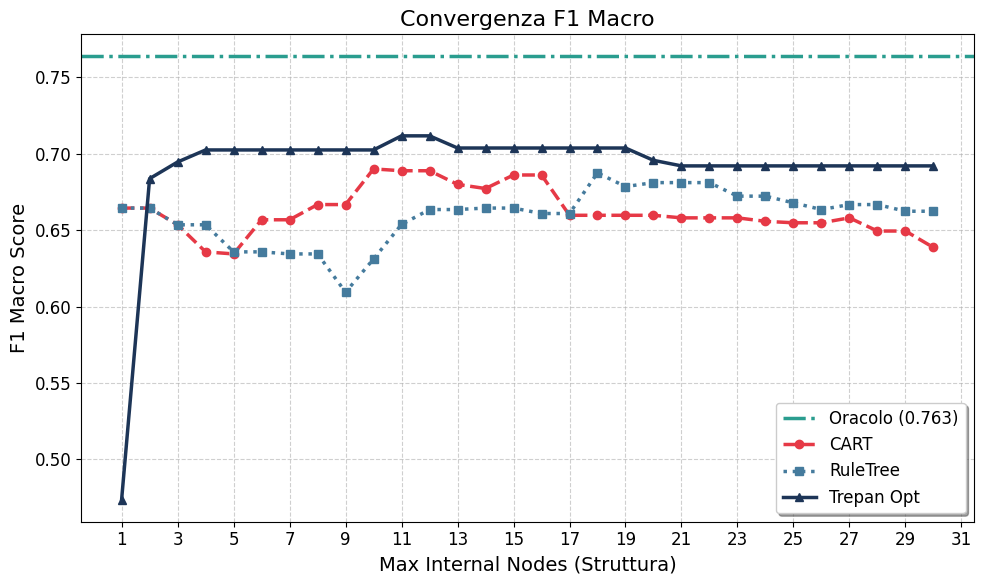

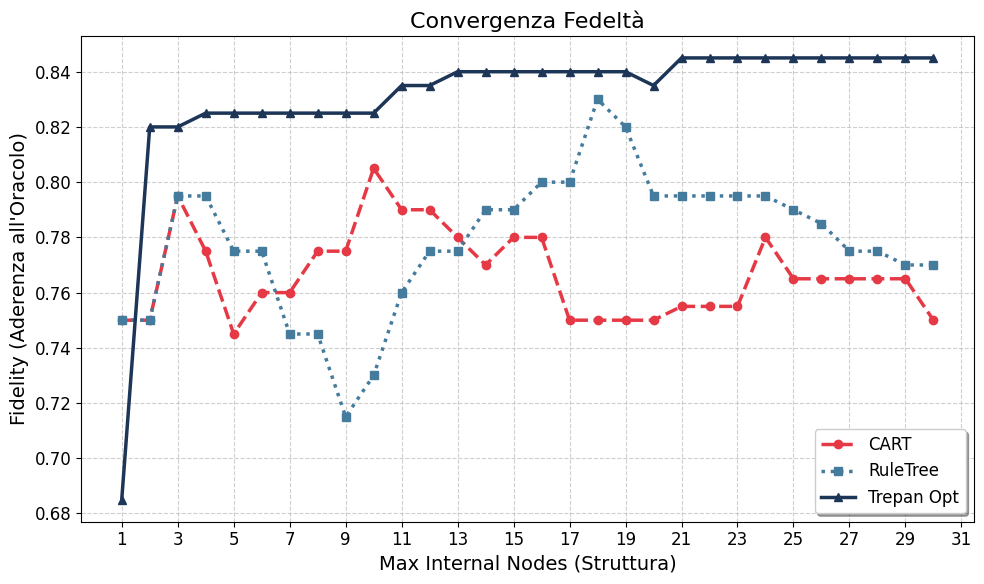

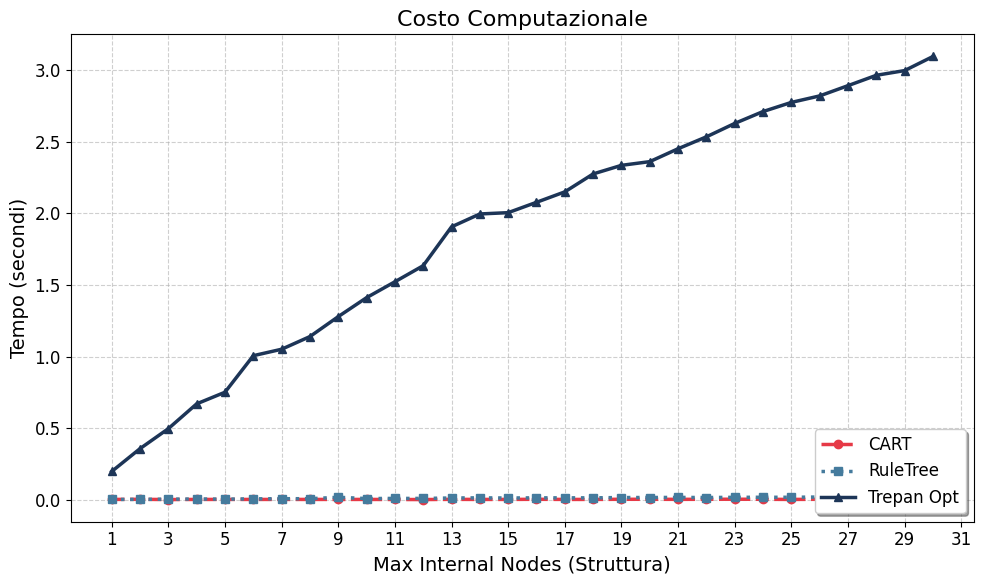

In [13]:
df = pd.DataFrame(results_all)
df = df.drop_duplicates(subset=["max_internal_nodes", "name"], keep="last").reset_index(drop=True)

df = df.rename(columns={
    'max_internal_nodes': 'Nodes',
    'name': 'Model',
    'accuracy': 'Acc',
    'balanced_accuracy': 'Bal_Acc',
    'f1_macro': 'F1_Macro',
    'fidelity': 'Fidelity',
    'time_s': 'Time'
})

# Calcolo esatto dell'F1 Macro dell'Oracolo (usa y_test e y_pred già presenti in memoria)
f1_oracle = f1_score(y_test, y_pred, average='macro')
print(f"F1 Macro dell'Oracolo: {f1_oracle:.3f}")

# Impostazioni di stile accademico per Matplotlib
plt.rcParams.update({
    'font.size': 12, 'axes.labelsize': 14, 'axes.titlesize': 16,
    'legend.fontsize': 12, 'lines.linewidth': 2.5, 'lines.markersize': 6
})

styles = {
    'CART': {'color': '#e63946', 'marker': 'o', 'linestyle': '--'},
    'RuleTree': {'color': '#457b9d', 'marker': 's', 'linestyle': ':'},
    'Trepan Opt': {'color': '#1d3557', 'marker': '^', 'linestyle': '-'}
}

def plot_metric_convergence(df, metric_col, ylabel, title, filename, oracle_val=None):
    fig, ax = plt.subplots(figsize=(10, 6))
    
    # Se viene passato il valore dell'Oracolo, traccia la linea orizzontale di riferimento
    if oracle_val is not None:
        ax.axhline(y=oracle_val, color='#2a9d8f', linestyle='-.', linewidth=2.5, 
                   label=f'Oracolo ({oracle_val:.3f})')

    for model_name in ['CART', 'RuleTree', 'Trepan Opt']:
        subset = df[df['Model'] == model_name]
        ax.plot(subset['Nodes'], subset[metric_col], 
                label=model_name, color=styles[model_name]['color'], 
                marker=styles[model_name]['marker'], linestyle=styles[model_name]['linestyle'])

    ax.set_xlabel('Max Internal Nodes (Struttura)')
    ax.set_ylabel(ylabel)
    ax.set_title(title)
    ax.set_xticks(np.arange(1, 32, 2))
    ax.grid(True, linestyle='--', alpha=0.6)
    ax.legend(loc='lower right', frameon=True, shadow=True)
    
    plt.tight_layout()
    plt.savefig(f"{filename}.pdf", dpi=300, bbox_inches='tight')
    plt.savefig(f"{filename}.png", dpi=300, bbox_inches='tight')
    plt.show()



# Genera e salva i grafici
print("\nGenerazione grafici in corso...")
plot_metric_convergence(df, 'F1_Macro', 'F1 Macro Score', 'Convergenza F1 Macro', 'german_f1_macro_plot', oracle_val=f1_oracle)
plot_metric_convergence(df, 'Fidelity', 'Fidelity (Aderenza all\'Oracolo)', 'Convergenza Fedeltà', 'german_fidelity_plot')
plot_metric_convergence(df, 'Time', 'Tempo (secondi)', 'Costo Computazionale', 'german_time_plot')